# 03 - Baselines (DataCo)
Two tasks, both with a **time-based split** (train = oldest 70%, validation = next 15%, test = newest 15%):
1. **Late-delivery classification** (`Late_delivery_risk`)
2. **ETA regression** (`Days for shipping (real)`)

Every later model in notebook 04 has to beat the best row of these tables.
Only pre-shipment columns are used as features (see `LEAKY_DATACO`).

In [1]:
import sys; sys.path.append("..")
import yaml, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.pipeline import Pipeline

from src.data.load import load_dataco
from src.data.clean import clean_dataco
from src.features.build_features import (
    DATACO_CAT, DATACO_NUM, LEAKY_DATACO, DATACO_TARGET_CLF, DATACO_TARGET_REG,
    DATACO_DATE_COL, build_dataco_features, make_preprocessor, time_split)
from src.models.evaluate import best_f1_threshold, evaluate_binary, evaluate_regression
from src.utils.plotting import plot_roc_pr

cfg = yaml.safe_load(open("../config.yaml")); SEED = cfg["seed"]
df = build_dataco_features(clean_dataco(load_dataco("../" + cfg["paths"]["dataco"])))
train, val, test = time_split(df, cfg["split"]["train"], cfg["split"]["val"])
out_tables = Path("../reports/tables"); out_tables.mkdir(parents=True, exist_ok=True)
out_figs = Path("../" + cfg["paths"]["figures"]); out_figs.mkdir(parents=True, exist_ok=True)
y = DATACO_TARGET_CLF

pd.DataFrame({
    "rows": [len(train), len(val), len(test)],
    "from": [d[DATACO_DATE_COL].min().date() for d in (train, val, test)],
    "to": [d[DATACO_DATE_COL].max().date() for d in (train, val, test)],
    "late_rate": [d[y].mean().round(3) for d in (train, val, test)],
}, index=["train", "val", "test"])

,rows,from,to,late_rate
train,126363,2015-01-01,2017-01-08,0.549
val,27078,2017-01-08,2017-06-14,0.541
test,27078,2017-06-14,2018-01-31,0.550


## 1. Late-delivery classification
Baselines, from dumbest to best:
- **constant**: predict the training late rate for everyone (ROC-AUC 0.5 by definition)
- **mode-only**: predict the training late rate of each shipping mode
- **logistic regression** and **random forest** on all pre-shipment features
- the same two models **without** shipping mode and scheduled days, to see what the remaining features add

The threshold for F1/precision/recall is tuned on the validation split only.

In [2]:
rows, test_probs = [], {}

def add_row(name, p_val, p_test):
    thr = best_f1_threshold(val[y], p_val)
    r = evaluate_binary(test[y], p_test, thr)
    rows.append({"model": name, **{k: r[k] for k in ["roc_auc", "pr_auc", "f1", "precision", "recall", "threshold"]}})
    test_probs[name] = np.asarray(p_test)

# constant baseline
base = train[y].mean()
add_row("constant (train late rate)", np.full(len(val), base), np.full(len(test), base))

# mode-only baseline
rate = train.groupby("Shipping Mode")[y].mean()
add_row("mode-only late rate",
        val["Shipping Mode"].map(rate).fillna(base), test["Shipping Mode"].map(rate).fillna(base))

FEATURE_SETS = {
    "all features": DATACO_CAT + DATACO_NUM,
    "no mode/scheduled": [c for c in DATACO_CAT + DATACO_NUM
                          if c not in ("Shipping Mode", "Days for shipment (scheduled)")],
}
for fs_name, feats in FEATURE_SETS.items():
    assert not set(feats) & set(LEAKY_DATACO), "leaky column in features"
    cat = [c for c in feats if c in DATACO_CAT]; num = [c for c in feats if c in DATACO_NUM]
    models = {
        "logistic regression": Pipeline([("prep", make_preprocessor(cat, num, scale=True)),
                                         ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
        "random forest": Pipeline([("prep", make_preprocessor(cat, num)),
                                   ("clf", RandomForestClassifier(n_estimators=150, min_samples_leaf=20,
                                                                  class_weight="balanced", n_jobs=-1, random_state=SEED))]),
    }
    for m_name, model in models.items():
        model.fit(train[feats], train[y])
        add_row(f"{m_name} ({fs_name})", model.predict_proba(val[feats])[:, 1], model.predict_proba(test[feats])[:, 1])

clf_results = pd.DataFrame(rows).set_index("model").round(3).sort_values("roc_auc", ascending=False)
clf_results.to_csv(out_tables / "baselines_dataco_classification.csv")
clf_results

,roc_auc,pr_auc,f1,precision,recall,threshold
model,,,,,,
random forest (all features),0.774,0.837,0.726,0.594,0.936,0.305
logistic regression (all features),0.748,0.819,0.718,0.599,0.895,0.309
mode-only late rate,0.731,0.750,0.710,0.550,1.000,0.381
logistic regression (no mode/scheduled),0.556,0.589,0.710,0.550,1.000,0.355
random forest (no mode/scheduled),0.551,0.584,0.710,0.550,1.000,0.316
constant (train late rate),0.500,0.550,0.710,0.550,1.000,0.549


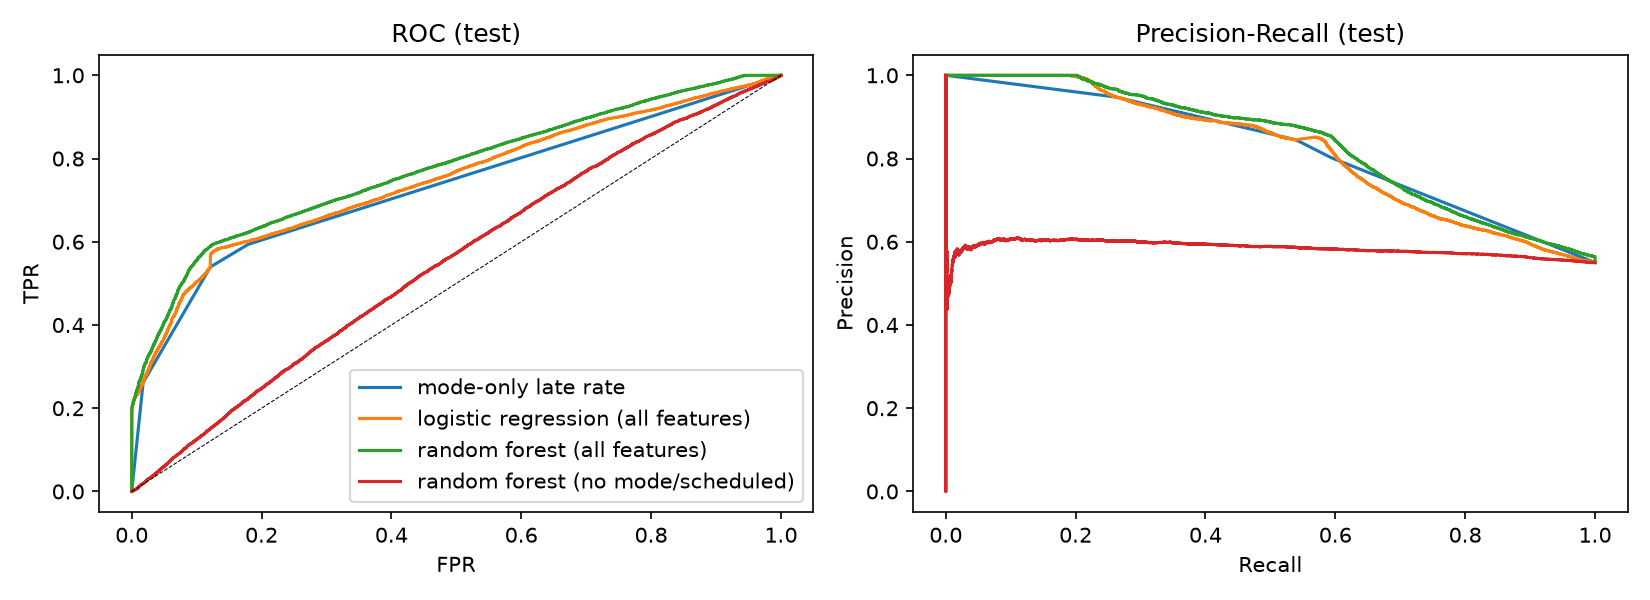

In [3]:
keep = ["mode-only late rate", "logistic regression (all features)", "random forest (all features)",
        "random forest (no mode/scheduled)"]
plot_roc_pr(test[y], {k: test_probs[k] for k in keep}, out_figs / "baselines_dataco_curves.png")
from IPython.display import Image; Image(out_figs / "baselines_dataco_curves.png")

**How to read this table**
- If a model's ROC-AUC is about the same as *mode-only*, the extra features added nothing.
- If *no mode/scheduled* is close to 0.5, then the other columns (region, product, payment type...) carry almost no signal.
- Class balance is about 55/45, so accuracy is not reported; use ROC-AUC, PR-AUC and F1.

## 2. ETA regression (`Days for shipping (real)`)
Baselines: predict the scheduled days, the mean real days per shipping mode, linear regression, random forest.

In [4]:
yr = DATACO_TARGET_REG
reg_rows = []
def add_reg(name, pred):
    reg_rows.append({"model": name, **evaluate_regression(test[yr], pred)})

add_reg("predict scheduled days", test["Days for shipment (scheduled)"])
mode_mean = train.groupby("Shipping Mode")[yr].mean()
add_reg("mean real days per mode", test["Shipping Mode"].map(mode_mean).fillna(train[yr].mean()))

feats = DATACO_CAT + DATACO_NUM
cat = [c for c in feats if c in DATACO_CAT]; num = [c for c in feats if c in DATACO_NUM]
assert not set(feats) & set(LEAKY_DATACO)
reg_models = {
    "linear regression": Pipeline([("prep", make_preprocessor(cat, num, scale=True)), ("reg", LinearRegression())]),
    "random forest": Pipeline([("prep", make_preprocessor(cat, num)),
                               ("reg", RandomForestRegressor(n_estimators=150, min_samples_leaf=20, n_jobs=-1, random_state=SEED))]),
}
for name, model in reg_models.items():
    model.fit(train[feats], train[yr]); add_reg(name, model.predict(test[feats]))

reg_results = pd.DataFrame(reg_rows).set_index("model").sort_values("mae")
reg_results.to_csv(out_tables / "baselines_dataco_eta.csv")
reg_results

,mae,rmse,r2
model,,,
random forest,0.9695,1.2658,0.3879
mean real days per mode,0.9808,1.2659,0.3878
linear regression,0.9921,1.2667,0.3871
predict scheduled days,1.2935,1.6000,0.0220


In [5]:
# Where does the error come from? Spread of real days within each mode (this is the noise floor).
test.groupby("Shipping Mode")[yr].agg(["mean", "std", "min", "max"]).round(2)

,mean,std,min,max
Shipping Mode,,,,
First Class,2.00,0.00,2,2
Same Day,0.56,0.50,0,1
Second Class,3.99,1.41,2,6
Standard Class,3.99,1.42,2,6


**Why the noise floor matters.** If real days inside a shipping mode are close to uniformly random, no model
can predict them better than the mode average. Then the useful contribution of notebook 04 is the
**prediction interval** (how uncertain the ETA is), not a lower MAE.

## Results to copy into `reports/experiment_log.md`
Best classifier: ...  ROC-AUC ...  PR-AUC ...  F1 ...
Mode-only baseline: ...
Best ETA model: ...  MAE ...  RMSE ...

## Takeaways (fill in)
1. 
2. 
3. 

In [6]:
print(pd.crosstab(df["Type"], df["Shipping Mode"], normalize="index").round(3))
print(pd.crosstab(df["Delivery Status"], df["Late_delivery_risk"]))

Shipping Mode  First Class  Same Day  Second Class  Standard Class
Type                                                              
CASH                 0.154     0.057         0.194           0.595
DEBIT                0.155     0.053         0.194           0.597
PAYMENT              0.149     0.052         0.201           0.597
TRANSFER             0.157     0.055         0.191           0.597
Late_delivery_risk      0      1
Delivery Status                 
Advance shipping    41592      0
Late delivery           0  98977
Shipping canceled    7754      0
Shipping on time    32196      0


In [7]:
print(pd.crosstab(df["Order Status"], df["Type"]))

Type              CASH  DEBIT  PAYMENT  TRANSFER
Order Status                                    
CANCELED             0      0        0      3692
CLOSED           19616      0        0         0
COMPLETE             0  59491        0         0
ON_HOLD              0   9804        0         0
PAYMENT_REVIEW       0      0     1893         0
PENDING              0      0        0     20227
PENDING_PAYMENT      0      0    39832         0
PROCESSING           0      0        0     21902
SUSPECTED_FRAUD      0      0        0      4062
